<a href="https://colab.research.google.com/github/owel569/Atelier2-CASANDRA/blob/main/01_CPU_PyTorch_ONNX_OpenVINO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP1 – Pipeline CPU n°1 : PyTorch → ONNX → OpenVINO Runtime → CPU

| Couche | Technologie |
|---|---|
| Haut niveau | PyTorch (ResNet-18 pré-entraîné ImageNet) |
| Format du modèle | ONNX |
| Middle level | OpenVINO Runtime (fusion d'opérateurs, sélection de kernels) |
| Bas niveau | kernels CPU optimisés (oneDNN) |
| Matériel | CPU Google Colab |

**Runtime Colab conseillé : CPU (Modifier > Paramètres du notebook > Aucun accélérateur).**
Exécuter toutes les cellules dans l'ordre. Le fichier `results/cpu1_pytorch_onnx_openvino.json` est produit à la fin ;
il sera ajouté au dépôt GitHub et lu par le notebook 05 (comparaison).

In [4]:
!pip -q install openvino onnx

In [5]:
import os, sys, time, json, hashlib, platform, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torchvision
from torchvision import transforms, datasets, models
from torchvision.transforms import InterpolationMode

# ====== PARAMÈTRES EXPÉRIMENTAUX (NE PAS MODIFIER : identiques dans les 4 notebooks) ======
SEED       = 42     # graine : même sous-ensemble de 50 images partout
N_IMAGES   = 50     # nombre d'images CIFAR-10 (jeu de test)
BATCH_SIZE = 10     # taille de batch (50 = 5 batchs)
IMG_SIZE   = 224    # taille d'entrée de ResNet-18
N_WARMUP   = 5      # passes de chauffe (exclues des mesures)
N_RUNS     = 5      # exécutions indépendantes (>= 3 exigé par l'énoncé)
N_PASSES   = 10     # nombre de passes sur les 50 images par exécution (mesures plus stables, énergie mesurable)
RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("torch", torch.__version__, "| torchvision", torchvision.__version__)

torch 2.14.1+cpu | torchvision 0.29.1+cpu


In [6]:
# ---------- Données : 50 images du jeu de test CIFAR-10 ----------
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck"]

# ResNet-18 a été pré-entraîné sur ImageNet (1000 classes), pas sur CIFAR-10.
# Pour calculer une précision Top-1 sur 10 classes, on associe chaque classe CIFAR-10
# à un groupe de classes ImageNet. Score d'une classe CIFAR = max des logits de son groupe.
IMAGENET_GROUPS = {
    "airplane":   [404, 895, 908],
    "automobile": [436, 468, 511, 609, 627, 656, 661, 751, 817],
    "bird":       list(range(7, 25)) + list(range(80, 101)) + list(range(127, 147)),
    "cat":        [281, 282, 283, 284, 285],
    "deer":       [351, 352, 353],
    "dog":        list(range(151, 269)),
    "frog":       [30, 31, 32],
    "horse":      [339, 603],
    "ship":       [403, 472, 484, 510, 554, 625, 628, 724, 780, 814, 833, 871, 914],
    "truck":      [555, 569, 675, 717, 734, 864, 867],
}
GROUPS = [np.array(IMAGENET_GROUPS[c]) for c in CIFAR_CLASSES]

def to_cifar(logits):
    """logits ImageNet (N,1000) -> classe CIFAR-10 prédite (N,)"""
    scores = np.stack([logits[:, g].max(axis=1) for g in GROUPS], axis=1)
    return scores.argmax(axis=1)

# Prétraitement identique à celui du pré-entraînement ImageNet : redimensionnement + normalisation
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

ds = datasets.CIFAR10(root="data", train=False, download=True)
idx = np.random.RandomState(SEED).choice(len(ds), N_IMAGES, replace=False).astype(np.int64)
labels = np.array([ds[int(i)][1] for i in idx])
X = torch.stack([tfm(ds[int(i)][0]) for i in idx]).contiguous()     # (50, 3, 224, 224) float32
SUBSET_HASH = hashlib.md5(idx.tobytes()).hexdigest()
print("X :", tuple(X.shape), X.dtype, "| hash du sous-ensemble :", SUBSET_HASH)
print("Répartition des classes :", dict(zip(CIFAR_CLASSES, np.bincount(labels, minlength=10).tolist())))

# Vérification visuelle des groupes (noms ImageNet réellement associés)
IN_NAMES = models.ResNet18_Weights.IMAGENET1K_V1.meta["categories"]
for c, g in zip(CIFAR_CLASSES, GROUPS):
    print(f"{c:11s} <- {len(g):3d} classes ImageNet, ex. : {[IN_NAMES[i] for i in g[:4]]}")

100%|██████████| 170M/170M [44:55<00:00, 63.3kB/s]


X : (50, 3, 224, 224) torch.float32 | hash du sous-ensemble : 3fb089145f7501be08d1825dfa25324f
Répartition des classes : {'airplane': 4, 'automobile': 4, 'bird': 7, 'cat': 5, 'deer': 3, 'dog': 9, 'frog': 5, 'horse': 4, 'ship': 5, 'truck': 4}
airplane    <-   3 classes ImageNet, ex. : ['airliner', 'warplane', 'wing']
automobile  <-   9 classes ImageNet, ex. : ['beach wagon', 'cab', 'convertible', 'jeep']
bird        <-  59 classes ImageNet, ex. : ['cock', 'hen', 'ostrich', 'brambling']
cat         <-   5 classes ImageNet, ex. : ['tabby', 'tiger cat', 'Persian cat', 'Siamese cat']
deer        <-   3 classes ImageNet, ex. : ['hartebeest', 'impala', 'gazelle']
dog         <- 118 classes ImageNet, ex. : ['Chihuahua', 'Japanese spaniel', 'Maltese dog', 'Pekinese']
frog        <-   3 classes ImageNet, ex. : ['bullfrog', 'tree frog', 'tailed frog']
horse       <-   2 classes ImageNet, ex. : ['sorrel', 'horse cart']
ship        <-  13 classes ImageNet, ex. : ['aircraft carrier', 'canoe', 'catam

In [7]:
# ---------- Modèle PyTorch pré-entraîné + référence (eager, CPU, FP32) ----------
WEIGHTS = models.ResNet18_Weights.IMAGENET1K_V1

def load_model():
    return models.resnet18(weights=WEIGHTS).eval()

ref_model = load_model()
with torch.inference_mode():
    ref_logits = torch.cat([ref_model(b) for b in X.split(BATCH_SIZE)]).numpy()
ref_pred = to_cifar(ref_logits)
print("Top-1 de référence (PyTorch eager CPU FP32) :", (ref_pred == labels).mean())

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 96.5MB/s]


Top-1 de référence (PyTorch eager CPU FP32) : 0.66


In [8]:
# ---------- Informations sur l'environnement (à citer dans le rapport) ----------
def _cpu_name():
    try:
        for l in open("/proc/cpuinfo"):
            if l.startswith("model name"):
                return l.split(":")[1].strip()
    except Exception:
        pass
    return platform.processor()

ENV = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "cpu": _cpu_name(),
    "cpu_count": os.cpu_count(),
    "torch_threads": torch.get_num_threads(),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "cuda": torch.version.cuda,
    "cudnn": torch.backends.cudnn.version() if torch.cuda.is_available() else None,
}
print(json.dumps(ENV, indent=2))

{
  "python": "3.13.18",
  "torch": "2.14.1+cpu",
  "torchvision": "0.29.1+cpu",
  "cpu": "Intel(R) Xeon(R) CPU @ 2.20GHz",
  "cpu_count": 2,
  "torch_threads": 1,
  "gpu": null,
  "cuda": null,
  "cudnn": null
}


In [9]:
# ---------- Mesure d'énergie (best effort) ----------
class EnergyMeter:
    """GPU : compteur d'énergie NVML (mJ).  CPU : compteur Intel RAPL si lisible.
    Si indisponible -> None (l'énoncé autorise 'lorsque les mesures sont disponibles')."""
    def __init__(self, kind):
        self.kind, self.ok = kind, False
        if kind == "gpu":
            try:
                import pynvml
                pynvml.nvmlInit()
                self.nv = pynvml
                self.h = pynvml.nvmlDeviceGetHandleByIndex(0)
                pynvml.nvmlDeviceGetTotalEnergyConsumption(self.h)
                self.ok = True
            except Exception as e:
                print("[énergie GPU indisponible]", e)
        else:
            self.p = "/sys/class/powercap/intel-rapl:0/"
            try:
                open(self.p + "energy_uj").read()
                self.max_j = int(open(self.p + "max_energy_range_uj").read()) / 1e6
                self.ok = True
            except Exception as e:
                print("[énergie CPU (RAPL) indisponible]", e)

    def read(self):
        if not self.ok: return None
        if self.kind == "gpu":
            return self.nv.nvmlDeviceGetTotalEnergyConsumption(self.h) / 1000.0
        return int(open(self.p + "energy_uj").read()) / 1e6

    def delta(self, a, b):
        if a is None or b is None: return None
        d = b - a
        if self.kind == "cpu" and d < 0: d += self.max_j
        return d


METRICS = ["throughput", "pass_s", "batch_ms", "img_ms", "energy_j", "energy_per_img_j", "power_w"]

def _stats(runs, key):
    v = [r[key] for r in runs if r.get(key) is not None]
    if len(v) == 0: return None
    v = np.array(v, dtype=float)
    return {"mean": float(v.mean()), "std": float(v.std(ddof=1)) if len(v) > 1 else 0.0,
            "min": float(v.min()), "max": float(v.max())}


def benchmark(pid, label, group, hw, infer_fn, build_time_s=None, is_main=True, extra=None):
    """infer_fn(batch_cpu_tensor) -> logits numpy (B,1000) sur CPU.
    La mesure inclut donc les transferts hôte<->device (même définition pour les 4 pipelines)."""
    batches = list(X.split(BATCH_SIZE))
    print(f"\n=== {label} ===")
    for _ in range(N_WARMUP):                       # chauffe (hors mesure)
        for b in batches: infer_fn(b)
    meter, runs, last_logits = EnergyMeter(hw), [], None
    n = N_IMAGES * N_PASSES
    for r in range(N_RUNS):
        lat, e0, t0 = [], meter.read(), time.perf_counter()
        for _ in range(N_PASSES):
            outs = []
            for b in batches:
                tb = time.perf_counter()
                outs.append(infer_fn(b))
                lat.append(time.perf_counter() - tb)
        t = time.perf_counter() - t0
        E = meter.delta(e0, meter.read())
        logits = np.concatenate(outs)
        if last_logits is not None:
            assert np.abs(logits - last_logits).max() < 1e-2, "sorties instables entre exécutions"
        last_logits = logits
        runs.append({
            "throughput": n / t,                   # images / s
            "pass_s": t / N_PASSES,                # temps pour traiter les 50 images (s)
            "batch_ms": 1000 * float(np.mean(lat)),# latence moyenne par batch (ms)
            "img_ms": 1000 * t / n,                # latence moyenne par image (ms)
            "energy_j": E,
            "energy_per_img_j": None if E is None else E / n,
            "power_w": None if E is None else E / t,
        })
        print(f"  run {r+1}/{N_RUNS} : {runs[-1]['throughput']:8.1f} img/s | {runs[-1]['pass_s']*1000:7.1f} ms / 50 img")
    pred = to_cifar(last_logits)
    result = {
        "id": pid, "label": label, "group": group, "hw": hw, "is_main": is_main,
        "build_time_s": build_time_s, "env": ENV, "extra": extra or {},
        "config": dict(SEED=SEED, N_IMAGES=N_IMAGES, BATCH_SIZE=BATCH_SIZE, N_WARMUP=N_WARMUP,
                       N_RUNS=N_RUNS, N_PASSES=N_PASSES, SUBSET_HASH=SUBSET_HASH),
        "runs": runs,
        "stats": {k: _stats(runs, k) for k in METRICS},
        "accuracy": {
            "top1": float((pred == labels).mean()),
            "agreement_with_ref": float((pred == ref_pred).mean()),
            "imagenet_argmax_agreement": float((last_logits.argmax(1) == ref_logits.argmax(1)).mean()),
            "max_abs_logit_diff_vs_ref": float(np.abs(last_logits - ref_logits).max()),
        },
        "predictions": pred.tolist(), "labels": labels.tolist(),
    }
    with open(f"{RESULTS_DIR}/{pid}.json", "w") as f:
        json.dump(result, f, indent=1)
    s = result["stats"]
    print(f"  -> débit {s['throughput']['mean']:.1f} ± {s['throughput']['std']:.1f} img/s | "
          f"Top-1 {result['accuracy']['top1']:.2%} | accord avec réf. {result['accuracy']['agreement_with_ref']:.2%}")
    return result


def summary_table(results):
    rows = []
    for r in results:
        row = {"pipeline": r["label"], "build (s)": r["build_time_s"]}
        for k, name in [("throughput", "img/s"), ("pass_s", "s/50img"), ("batch_ms", "ms/batch"), ("energy_per_img_j", "J/img")]:
            s = r["stats"][k]
            row[name + " moy"] = None if s is None else s["mean"]
            row[name + " std"] = None if s is None else s["std"]
            row[name + " min"] = None if s is None else s["min"]
            row[name + " max"] = None if s is None else s["max"]
        row["Top-1"] = r["accuracy"]["top1"]
        row["accord réf."] = r["accuracy"]["agreement_with_ref"]
        rows.append(row)
    return pd.DataFrame(rows).set_index("pipeline").T


def plot_own(results, fname):
    """Graphiques propres à ce notebook (la comparaison des 4 pipelines est dans le notebook 05)."""
    labs = [r["label"] for r in results]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    m = [r["stats"]["throughput"]["mean"] for r in results]
    s = [r["stats"]["throughput"]["std"] for r in results]
    ax[0].bar(labs, m, yerr=s, capsize=5, color="tab:blue"); ax[0].set_ylabel("images / s"); ax[0].set_title("Débit (moyenne ± écart-type)")
    m = [r["stats"]["pass_s"]["mean"] * 1000 for r in results]
    s = [r["stats"]["pass_s"]["std"] * 1000 for r in results]
    ax[1].bar(labs, m, yerr=s, capsize=5, color="tab:orange"); ax[1].set_ylabel("ms pour 50 images"); ax[1].set_title("Temps d'inférence (50 images)")
    for r in results:
        ax[2].plot(range(1, N_RUNS + 1), [x["throughput"] for x in r["runs"]], "o-", label=r["label"])
    ax[2].set_xlabel("exécution"); ax[2].set_ylabel("images / s"); ax[2].set_title("Variabilité run par run"); ax[2].legend(fontsize=7)
    for a in ax[:2]: a.tick_params(axis="x", rotation=15)
    plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig(f"figures/{fname}", dpi=150); plt.show()


def download_results():
    try:
        from google.colab import files
        import shutil
        shutil.make_archive("results_export", "zip", RESULTS_DIR)
        files.download("results_export.zip")
    except Exception as e:
        print("Hors Colab / téléchargement impossible :", e, "-> récupère le dossier results/ à la main.")

## 1. Export PyTorch → ONNX

In [10]:
# ---------- Export PyTorch -> ONNX (batch fixe = BATCH_SIZE) ----------
import onnx
ONNX_PATH = "resnet18.onnx"
m_export = load_model()
t0 = time.perf_counter()
try:
    torch.onnx.export(m_export, X[:BATCH_SIZE], ONNX_PATH, input_names=["input"], output_names=["logits"],
                      opset_version=17, dynamo=False)
except TypeError:   # anciennes versions de torch : pas d'argument dynamo
    torch.onnx.export(m_export, X[:BATCH_SIZE], ONNX_PATH, input_names=["input"], output_names=["logits"],
                      opset_version=17)
onnx_export_s = time.perf_counter() - t0
onnx.checker.check_model(onnx.load(ONNX_PATH))
print(f"ONNX exporté en {onnx_export_s:.2f}s | taille : {os.path.getsize(ONNX_PATH)/1e6:.1f} Mo")

/tmp/ipykernel_537/3150183871.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m_export, X[:BATCH_SIZE], ONNX_PATH, input_names=["input"], output_names=["logits"],


ONNX exporté en 3.51s | taille : 46.7 Mo


## 2. Compilation avec OpenVINO Runtime (CPU)
OpenVINO lit le graphe ONNX, applique ses transformations (fusion Conv+BN+ReLU, constant folding, etc.) puis
compile pour le plugin CPU, qui s'appuie sur oneDNN. On compare le nombre d'opérateurs avant/après compilation
pour illustrer la fusion d'opérateurs.

In [11]:
import openvino as ov
print("OpenVINO", ov.__version__)
ENV["openvino"] = ov.__version__
core = ov.Core()
print("Devices :", core.available_devices)

ov_model = core.read_model(ONNX_PATH)
t0 = time.perf_counter()
compiled = core.compile_model(ov_model, "CPU", {"PERFORMANCE_HINT": "LATENCY"})
ov_compile_s = time.perf_counter() - t0
print(f"compile_model : {ov_compile_s:.2f}s | EXECUTION_DEVICES = {compiled.get_property('EXECUTION_DEVICES')}")

try:
    n_before = len(ov_model.get_ops())
    n_after = len(compiled.get_runtime_model().get_ops())
    print(f"Opérateurs : {n_before} (graphe importé) -> {n_after} (graphe d'exécution après fusions)")
except Exception as e:
    n_before = n_after = None
    print("Comptage d'opérateurs indisponible :", e)

def infer_openvino(x):
    return np.array(compiled([x.numpy()])[0])

OpenVINO 2026.4.1-22982-e213a147257-releases/2026/4
Devices : ['CPU']
compile_model : 0.12s | EXECUTION_DEVICES = ['CPU']
Opérateurs : 305 (graphe importé) -> 112 (graphe d'exécution après fusions)


## 3. Mesures (5 exécutions indépendantes)

In [12]:
res_ov = benchmark(
    pid="cpu1_pytorch_onnx_openvino",
    label="CPU 1 : PyTorch→ONNX→OpenVINO",
    group="cpu1", hw="cpu", infer_fn=infer_openvino,
    build_time_s=onnx_export_s + ov_compile_s,
    extra={"onnx_export_s": onnx_export_s, "ov_compile_s": ov_compile_s,
           "ops_before_fusion": n_before, "ops_after_fusion": n_after,
           "hint": "LATENCY"},
)
summary_table([res_ov])


=== CPU 1 : PyTorch→ONNX→OpenVINO ===
[énergie CPU (RAPL) indisponible] [Errno 2] No such file or directory: '/sys/class/powercap/intel-rapl:0/energy_uj'
  run 1/5 :     17.4 img/s |  2876.5 ms / 50 img
  run 2/5 :     17.1 img/s |  2924.9 ms / 50 img
  run 3/5 :     17.6 img/s |  2836.8 ms / 50 img
  run 4/5 :     17.6 img/s |  2841.7 ms / 50 img
  run 5/5 :     17.2 img/s |  2913.7 ms / 50 img
  -> débit 17.4 ± 0.2 img/s | Top-1 66.00% | accord avec réf. 100.00%


pipeline,CPU 1 : PyTorch→ONNX→OpenVINO
build (s),3.637201
img/s moy,17.371663
img/s std,0.2429
img/s min,17.094466
img/s max,17.625667
s/50img moy,2.878701
s/50img std,0.040285
s/50img min,2.836772
s/50img max,2.924923
ms/batch moy,575.737421


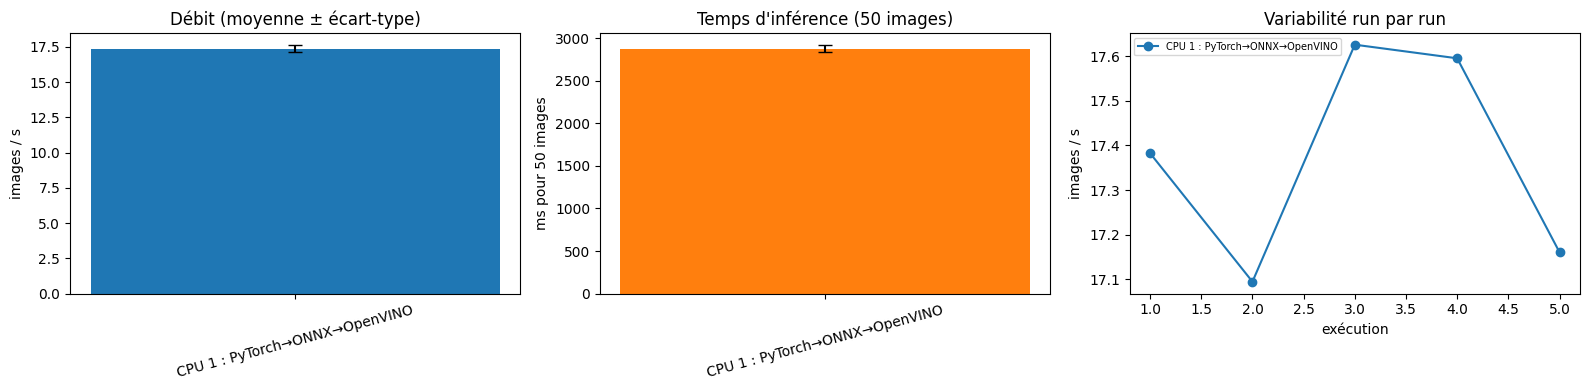

In [13]:
plot_own([res_ov], "cpu1_openvino.png")

## 4. Analyse (à rédiger pour le rapport)
- Les 5 exécutions sont-elles stables (écart-type / moyenne) ? Y a-t-il des valeurs aberrantes (voisins bruyants sur Colab) ?
- Quel gain apporte la fusion d'opérateurs (comparer le nombre d'ops avant/après) ?
- La précision Top-1 et l'accord avec la référence PyTorch sont-ils inchangés par la conversion ONNX + OpenVINO ?
- Coût de mise en place (export + compilation) amorti au bout de combien d'images ?

In [14]:
download_results()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>